In [1]:
import numpy as np
import matplotlib.pyplot as plt

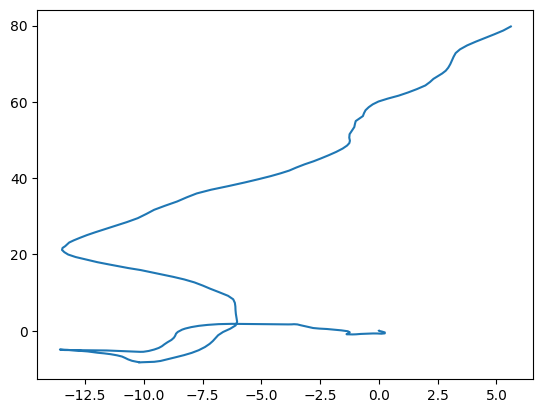

In [2]:
dt = 0.1
n_steps = 200

def generate_motion(
    n_steps=100,
    dt=0.1,
    initial_position=(0.0, 0.0),
    initial_velocity=(0.0, 0.0),
    acceleration_std=0.5,
    seed=174
):
    """
    Generate synthetic 2D motion with randomly changing acceleration.

    Returns
    -------
    output : ndarray, shape (n_steps, 6)
        State vector output
        Columns: [px, vx, ax, py, vy, ay]
    """
    rng = np.random.default_rng(seed)

    output = np.zeros((n_steps, 6)) # state vector

    # Initial state: [px, vx, ax, py, vy, ay]
    output[0] = [
        initial_position[0], initial_velocity[0], 0.0,
        initial_position[1], initial_velocity[1], 0.0
    ]

    for k in range(1, n_steps):
        px, vx, _, py, vy, _ = output[k - 1]

        # Random acceleration in each axis
        ax = rng.normal(0, acceleration_std)
        ay = rng.normal(0, acceleration_std)

        # Update position and velocity
        output[k] = [
            px + vx * dt + 0.5 * ax * dt**2, vx + ax * dt, ax,
            py + vy * dt + 0.5 * ay * dt**2, vy + ay * dt, ay
        ]

    return output

gt_states = generate_motion(n_steps=n_steps, dt=0.1, initial_velocity=[-1,1], seed = 3, acceleration_std = 10)
plt.plot(gt_states[:,0],gt_states[:,3],'-')

# Measurement

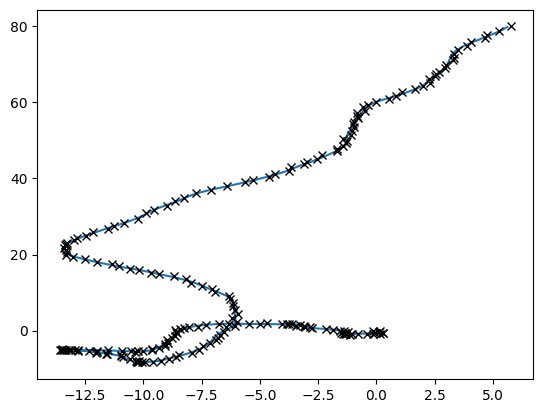

In [24]:
sig = 0.1
Q_meas = np.array([
    [sig**2, 0],
    [0, sig**2],
])
meas_states = gt_states[:, [0,3]] + np.random.multivariate_normal(mean=np.zeros(2), cov=Q_meas, size= len(gt_states))
plt.plot(gt_states[:,0],gt_states[:,3],'-')
plt.plot(meas_states[:,0],meas_states[:,1],'kx')

# Kalman: Accomodate for acceleration

For each axis, define the state vector as:

$$
\mathbf{x}_k =
\begin{bmatrix}
p \\
v \\
a
\end{bmatrix}
$$

The transition matrix becomes:

$$
F =
\begin{bmatrix}
1 & \Delta t & \frac{1}{2}\Delta t^2 \\
0 & 1 & \Delta t \\
0 & 0 & 1
\end{bmatrix}
$$


In [35]:
dt = 0.1 # timestep
q = 0.05 # process noise

v0 = 0 # initial state guess
a0 = 0 # initial state guess

# Motion transition model
F = np.array([
    [1, dt, dt**2/2, 0, 0, 0],
    [0, 1, dt, 0, 0, 0],
    [0, 0, 1, 0, 0, 0,],
    [0, 0, 0, 1, dt, dt**2],
    [0, 0, 0, 0, 1, dt],
    [0, 0, 0, 0, 0, 1],
]) 

# Measurement mapping (measurements only measure positions )
# Measurement model will be z = H@x + v, where v has covariance matrix R
H = np.array([
    [1, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0],
])

# Process noise covariance (accounting for random accelerations)
# "continuous white jerk noise".. assumes there's some smooth variation of accel.
Q = np.zeros((6, 6))
Q_1d = q*np.array([
    [dt**5/20, dt**4/8, dt**3/6],
    [dt**4/8, dt**3/3, dt**2/2],
    [dt**3/6, dt**2/2, dt]
])
Q[np.ix_([0, 1, 2], [0, 1, 2])] = Q_1d
Q[np.ix_([3, 4, 5], [3, 4, 5])] = Q_1d

# Measurement noise covariance
R = np.array([
    [sig**2, 0],
    [0, sig**2]
])

# Initial state guess
x_prev = np.array([
    [meas_states[0][0]],
    [v0],
    [a0],
    [meas_states[0][1]],
    [v0],
    [a0],
])

# Initial uncertainty
sig_p0 = 1
sig_v0 = 1
sig_a0 = 0

P_prev = np.diag([
    sig_p0**2,
    sig_v0**2,
    sig_a0**2,
    sig_p0**2,
    sig_v0**2,
    sig_a0**2,
])

xs_list = [x_prev]
Ps_list = [P_prev]

zs_list = np.expand_dims(meas_states,1).transpose(0,2,1) ## need column vectors

# discard initial measurement, because we've directly used this z in prediction
for z in zs_list[1:]:
    ## 1. PREDICT STATE
    # x is state for step k, given state for k-1
    # F is transition model
    # x_prev is previous state
    x = F@x_prev
    
    # uncertainty
    # P here is the uncertainty (not probability) of state k given state k-1 happened
    # P_prev is uncertainty (not probability) in previous state
    # Q is the uncertainty due to unpredictable motion (random acceleration, for example)
    P = F@P_prev@F.T + Q
    
    ## 2. COMPARE WITH MEASUREMENT
    
    # y is "innovation" for step k
    # z is measurement for step k
    # x is state for step k, given state for k-1
    # H@x is predicted measurement
    y = z - H@x
    
    # Kalman gain
    # S is innovation covartiance for step k
    # P here is uncertainty (not probability) of state k given state k-1 happened
    # R is measurement noise covariance
    # K is Kalman gain
    S = H@P@H.T + R
    K = P@H.T@np.linalg.inv(S)
    
    ## 3. CORRECT THE STATE ESTIMATE
    # Updated estimate (x_new) equals predicted state (x) plus kalman gain (K) times innovation (y)
    x_new = x + K@y
    
    ## 4. UPDATE THE UNCERTAINTY
    # P here is the uncertainty (not probability) of state k given state k-1 happened
    
    P_new = P - K@H@P
    #    # "Joseph form", apparently has better floating point arithmetic
    #    I = np.eye(P.shape[0])
    #
    #    P_new = (
    #        (I - K @ H) @ P @ (I - K @ H).T
    #        + K @ R @ K.T
    #    )

    ## 5. PREP FOR NEXT ITERATION
    x_prev = x_new
    P_prev = P_new

    xs_list.append(x_new)
    Ps_list.append(P_new)

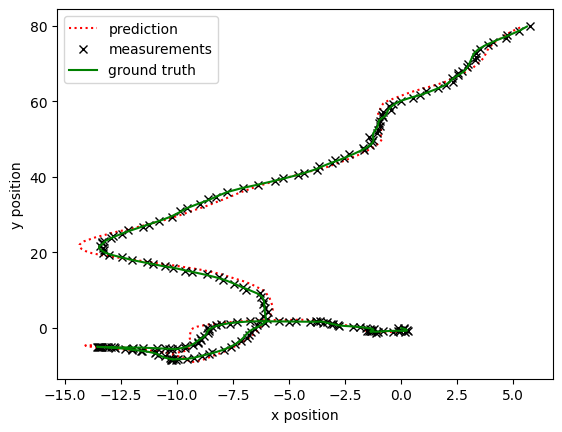

In [36]:
pred_state_x = np.array([_[0] for _ in xs_list])[:,0]
pred_state_y = np.array([_[3] for _ in xs_list])[:,0]
meas_state_x = np.array([_[0] for _ in meas_states])
meas_state_y = np.array([_[1] for _ in meas_states])
gt_state_x = np.array([_[0] for _ in gt_states])
gt_state_y = np.array([_[3] for _ in gt_states])

plt.figure()
plt.plot(pred_state_x, pred_state_y , 'r:')
plt.plot(meas_state_x, meas_state_y , 'kx')
plt.plot(gt_state_x, gt_state_y , 'g-')
plt.xlabel("x position")
plt.ylabel("y position")
plt.legend(["prediction", "measurements", "ground truth"])

pos_err_x = meas_state_x - pred_state_x
pos_err_y = meas_state_y - pred_state_y

# plt.figure()
# plt.plot(pos_err_x)
# plt.plot(pos_err_y)
# plt.xlabel("step")
# plt.ylabel("error")
# plt.legend(["x pos", "y pos"])